In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, PASTEL_CMAP, set_font_size
GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

# Gaussian Repulsion — Moving Obstacle

The Gaussian center circles the tip spring's fixed target (radius 10 cm) while the
tip spring (`lin_seg3`) tries to hold its reference at the origin, for two spring
stiffnesses: k = 2 N/m and k = 20 N/m.

**Goal:** overlay the end-effector path against the moving Gaussian goal, colored by
time, to compare how much the softer spring gets dragged along by the repulsion versus
the stiffer spring holding its ground.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection
import os

In [3]:

def load_circle_window(path: str):
    """Return (t, ee_xy, gauss_xy) arrays trimmed to the circling phase, positions in cm."""
    d = np.load(path)
    t        = d['t']
    goal     = d['goal']      # (n, N_VC, 3)
    comp_pos = d['comp_pos']  # (n, N_VC, 3)

    # Circle starts when |gauss_goal_y| first exceeds 2 mm, ends when it last does
    gauss_goal_y = goal[:, 1, 1]
    mask = np.abs(gauss_goal_y) > 0.002
    idx_start = np.where(mask)[0][0]
    idx_end   = np.where(mask)[0][-1]

    sl = slice(idx_start, idx_end + 1)
    t_w        = t[sl] - t[idx_start]                # zero-based time
    ee_xy      = comp_pos[sl, 0, :2] * 100.0          # (n, 2)  lin_seg3 end-effector [m -> cm]
    gauss_xy   = goal[sl, 1, :2] * 100.0              # (n, 2)  gaussian goal [m -> cm]

    return t_w, ee_xy, gauss_xy


def make_segments(xy: np.ndarray):
    """Convert (n, 2) path into (n-1, 2, 2) line segments for LineCollection."""
    pts = xy.reshape(-1, 1, 2)
    return np.concatenate([pts[:-1], pts[1:]], axis=1)


# Line weights matched to plot_gauss_fixed_gauss.ipynb's convention: bold for
# the primary data curve (BACKBONE_LW there = 4.0), lighter for guide/context
# lines (its dashed spring connectors = 1.4). The old values here (1.8 / 1.0 /
# 0.8) were much thinner than that and read as broken/washed out next to it.
EE_LW   = 3.5   # primary: end-effector path
GOAL_LW = 2.0   # secondary: gaussian goal path (still behind EE via alpha)
REF_LW  = 1.4   # background: reference circle guide


def draw_panel(ax, t, ee_xy, gauss_xy, title: str, show_ylabel=True, cmap=PASTEL_CMAP):
    norm = mcolors.Normalize(vmin=0, vmax=t[-1])

    # Reference circle (radius 10 cm)
    theta = np.linspace(0, 2 * np.pi, 300)
    ax.plot(10.0 * np.cos(theta), 10.0 * np.sin(theta),
            '--', color='gray', linewidth=REF_LW, alpha=0.5, label='R = 10 (cm) ref')

    # Origin
    ax.plot(0, 0, 'k+', markersize=8, markeredgewidth=1.5, label='Origin')

    # Gaussian goal path
    segs_g = make_segments(gauss_xy)
    lc_g = LineCollection(segs_g, cmap=cmap, norm=norm,
                          linewidth=GOAL_LW, alpha=0.45, zorder=2)
    lc_g.set_array(0.5 * (t[:-1] + t[1:]))
    ax.add_collection(lc_g)
    # ghost handle for legend
    ax.plot([], [], color=cmap(0.5), linewidth=GOAL_LW, alpha=0.55, label='Gauss goal')

    # End-effector path -- color encodes time, see the shared colorbar
    segs_e = make_segments(ee_xy)
    lc_e = LineCollection(segs_e, cmap=cmap, norm=norm,
                          linewidth=EE_LW, zorder=3)
    lc_e.set_array(0.5 * (t[:-1] + t[1:]))
    ax.add_collection(lc_e)

    # In-panel label instead of a title -- the only thing telling the two panels apart
    ax.text(0.03, 0.97, title, transform=ax.transAxes, ha='left', va='top',
            fontsize=plt.rcParams['axes.labelsize'], fontweight='bold')
    ax.set_xlabel('X (cm)')
    # Shared y-axis: only the left panel gets the label and the tick numbers,
    # so the right panel doesn't repeat them (paired-plot alignment).
    if show_ylabel:
        ax.set_ylabel('Y (cm)')
    else:
        ax.tick_params(labelleft=False)
    ax.set_aspect('equal')
    ax.grid(GRID)

    lim = 16.0
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)

    return lc_e  # return for shared colorbar


In [4]:
files = {
    'K = 2 (N/m)':  os.path.join('outputs', 'moving_gauss', 'k2_moving_gauss.npz'),
    'K = 20 (N/m)': os.path.join('outputs', 'moving_gauss', 'k20_moving_gauss.npz'),
}

# Print the details behind each panel before plotting: full-run length, the
# detected circling-phase window, and a sanity check that the end-effector
# actually orbits close to the 10 cm reference radius.
for title, path in files.items():
    d = np.load(path)
    fs = float(d['control_freq'][0])
    t_w, ee_xy, gauss_xy = load_circle_window(path)
    r_ee = np.linalg.norm(ee_xy, axis=1)
    print(f'{title}   [{path}]')
    print(f'  Full run:        {len(d["t"])} samples   {d["t"][-1]:.1f} s   fs={fs:.0f} Hz')
    print(f'  Circling window: {len(t_w)} samples   {t_w[-1]:.2f} s')
    print(f'  EE radius range: [{r_ee.min():.2f}, {r_ee.max():.2f}] cm   (ref = 10.00 cm)')
    print()

K = 2 (N/m)   [outputs\moving_gauss\k2_moving_gauss.npz]
  Full run:        10751 samples   37.0 s   fs=330 Hz
  Circling window: 6534 samples   19.80 s
  EE radius range: [4.87, 9.29] cm   (ref = 10.00 cm)

K = 20 (N/m)   [outputs\moving_gauss\k20_moving_gauss.npz]
  Full run:        17863 samples   58.4 s   fs=330 Hz
  Circling window: 6534 samples   19.80 s
  EE radius range: [3.78, 4.81] cm   (ref = 10.00 cm)



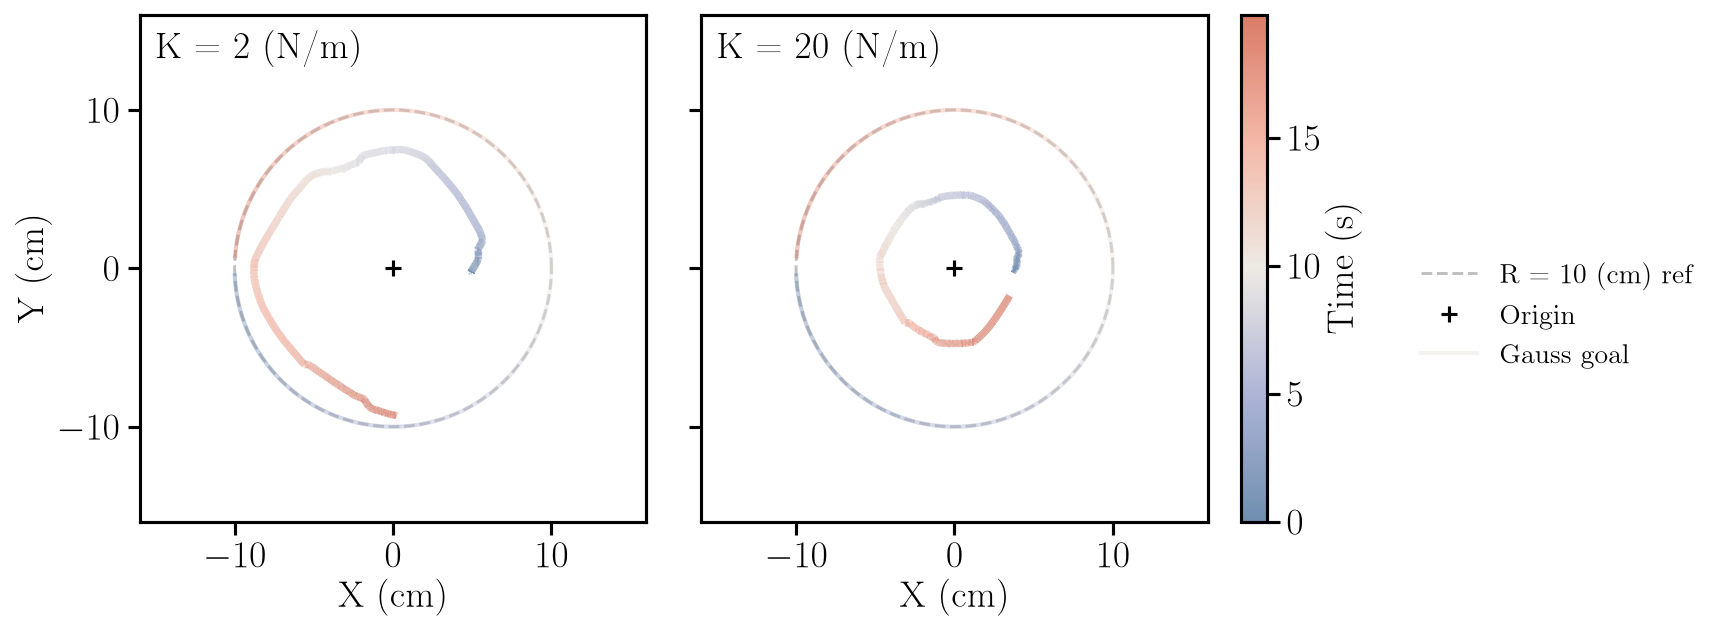

Saved → outputs\moving_gauss\xy_circle_comparison.pdf


In [5]:

# ---- size / aspect for THIS graph only ----
# Match plot_gauss_fixed_gauss.ipynb's TOTAL figure width (9in). Both figures
# get viewed/embedded at a common display width, so what keeps the 18pt font
# reading the same size across the two companion figures is equal total
# width -- not equal per-panel width (a wider total figure just gets scaled
# down more to fit, shrinking its text relative to the narrower one).
W_IN   = 9.0    # inches -- matches plot_gauss_fixed_gauss.ipynb exactly
ASPECT = 5 / 11
H_IN   = W_IN * ASPECT

fig, axes = plt.subplots(1, 2, figsize=(W_IN, H_IN), layout='constrained')

last_lc = None
handles, labels = None, None

for i, (ax, (title, path)) in enumerate(zip(axes, files.items())):
    t, ee_xy, gauss_xy = load_circle_window(path)
    lc = draw_panel(ax, t, ee_xy, gauss_xy, title, show_ylabel=(i == 0))
    last_lc = lc
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

# Shared colorbar (time axis)
cbar = fig.colorbar(last_lc, ax=axes, orientation='vertical',
                    fraction=0.025, pad=0.03, label='Time (s)')

# One legend for both panels (identical content, so drawn once) -- placed just
# past the colorbar with room to breathe, instead of cramped into each panel's corner.
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.03, 0.5),
          frameon=False, borderaxespad=0)

out = os.path.join('outputs', 'moving_gauss', 'xy_circle_comparison.pdf')
fig.savefig(out)
plt.show()
print(f"Saved → {out}")
